# 02 — So sánh và đánh giá mô hình được chọn
Gom mọi run đã xong thành bảng + biểu đồ cho slide, chọn mô hình cuối theo **validation accuracy**,
rồi hiệu chỉnh độ tin cậy (temperature scaling trên validation) và xem 15 ảnh sai tự tin nhất.

## 0. Chuẩn bị phiên (Colab hoặc máy M4)
Chạy cell này **mỗi lần mở notebook** (kể cả sau khi bị ngắt). Cell tự nhận biết đang ở đâu:
- **Colab:** mount Drive, copy code về `/content/vnfood`, kiểm tra code khớp bản Claude vừa sync (hash) và GPU T4 (*Runtime → Change runtime type → T4 GPU*). Nếu Claude sync lại trong lúc notebook đang mở: *Runtime → Restart session* rồi chạy lại từ cell này.
- **Máy (M4):** chạy thẳng trên repo, kernel `vnfood (.venv)`, GPU `mps`. Kết quả vẫn ghi vào thư mục Drive (bật Drive for Desktop).

In [1]:
import sys
from pathlib import Path
ON_COLAB = "google.colab" in sys.modules
if ON_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    import shutil
    shutil.copytree("/content/drive/MyDrive/DL/vnfood_colab/code", "/content/vnfood", dirs_exist_ok=True,
                    ignore=shutil.ignore_patterns("data", "models"))
    REPO = Path("/content/vnfood")
else:
    REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "colab" / "session.py").is_file())
sys.path.insert(0, str(REPO))
from colab import session
env = session.start(REPO, ON_COLAB)
RUNS, MANIFEST, DEVICE = env["runs"], env["manifest"], env["device"]

Runs: /Users/thanhhhtt/Library/CloudStorage/GoogleDrive-hahiepthanhhhtt@gmail.com/My Drive/DL/vnfood_colab/runs
Thiết bị: mps (Apple M4 Pro)


In [2]:
if not session.restore_data(REPO, env["data"], manifest_dst=MANIFEST):
    raise SystemExit("Chưa có data trên Drive — chạy notebook 00 trước.")
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image as Show, display
from colab import compare
rows = compare.collect(RUNS)
out = RUNS / "_compare"
compare.write_comparison(rows, out)
pd.DataFrame(rows).drop(columns=["run_dir"]).round(4)

,run_id,exp,arch,pretrained,freeze_backbone,augment,lr,label_smoothing,seed,device,best_val_accuracy,test_accuracy,macro_f1,top3_accuracy,params,train_seconds,gpu_images_per_sec,cpu_ms_per_image
0,E1_cnn,E1,cnn,False,False,True,0.0010,0.05,42,Tesla T4,0.6121,0.6097,0.5974,0.8214,397086,4380.9999,1394.7042,38.9154
1,E4_efficientnet_b0,E4,efficientnet_b0,True,False,True,0.0003,0.00,42,Tesla T4,0.8878,0.8831,0.8852,0.9656,4045978,3736.5736,862.1897,35.1419
2,E2_resnet50,E2,resnet50,True,False,True,0.0003,0.00,42,Tesla T4,0.8928,0.8879,0.8895,0.9664,23569502,3857.6815,323.5257,122.0972
3,E3_mobilenet_v3_large,E3,mobilenet_v3_large,True,False,True,0.0003,0.00,42,Tesla T4,0.8824,0.8796,0.8804,0.9634,4240462,3587.7196,1434.9614,21.0676
4,C1_resnet50_m4,C1,resnet50,True,False,True,0.0003,0.00,42,mps (Apple M4 Pro),0.8920,0.9007,0.9030,0.9698,23569502,2465.8833,319.7311,12.9689
5,T1_resnet50_frozen,T1,resnet50,True,True,True,0.0003,0.00,42,mps (Apple M4 Pro),0.7289,0.7459,0.7500,0.9063,23569502,938.3848,310.0707,12.8582
6,T3_resnet50_noaug,T3,resnet50,True,False,False,0.0003,0.00,42,mps (Apple M4 Pro),0.8824,0.8863,0.8873,0.9634,23569502,2602.5004,300.8042,12.9383
7,T2_resnet50_scratch,T2,resnet50,False,False,True,0.0003,0.00,42,mps (Apple M4 Pro),0.6700,0.6818,0.6752,0.8625,23569502,2562.9457,273.2893,13.0028
8,T4a_resnet50_lr1e-3,T4a,resnet50,True,False,True,0.0010,0.00,42,mps (Apple M4 Pro),0.8776,0.8783,0.8778,0.9656,23569502,2539.1244,305.1498,12.7834
9,T4b_resnet50_lr1e-4,T4b,resnet50,True,False,True,0.0001,0.00,42,mps (Apple M4 Pro),0.8907,0.8914,0.8930,0.9680,23569502,2614.5827,305.7793,13.0301


In [3]:
effect = compare.hardware_effect(rows, RUNS)
if effect:
    print(f"Ảnh hưởng phần cứng: {effect['base']} ({effect['base_device']}) − {effect['control']} ({effect['control_device']}): "
          f"val {effect['delta_val'] * 100:+.2f}, test {effect['delta_test'] * 100:+.2f} điểm %")
pd.DataFrame(compare.tuning_deltas(rows, RUNS)).round(4)

Ảnh hưởng phần cứng: E2_resnet50 (Tesla T4) − C1_resnet50_m4 (mps (Apple M4 Pro)): val +0.08, test -1.28 điểm %


,run_id,device,reference,delta_val,delta_test
0,T1_resnet50_frozen,mps (Apple M4 Pro),C1_resnet50_m4,-0.1631,-0.1548
1,T3_resnet50_noaug,mps (Apple M4 Pro),C1_resnet50_m4,-0.0096,-0.0144
2,T2_resnet50_scratch,mps (Apple M4 Pro),C1_resnet50_m4,-0.2221,-0.2189
3,T4a_resnet50_lr1e-3,mps (Apple M4 Pro),C1_resnet50_m4,-0.0145,-0.0224
4,T4b_resnet50_lr1e-4,mps (Apple M4 Pro),C1_resnet50_m4,-0.0013,-0.0093
5,T5_resnet50_ls0.1,mps (Apple M4 Pro),C1_resnet50_m4,0.0008,-0.0141


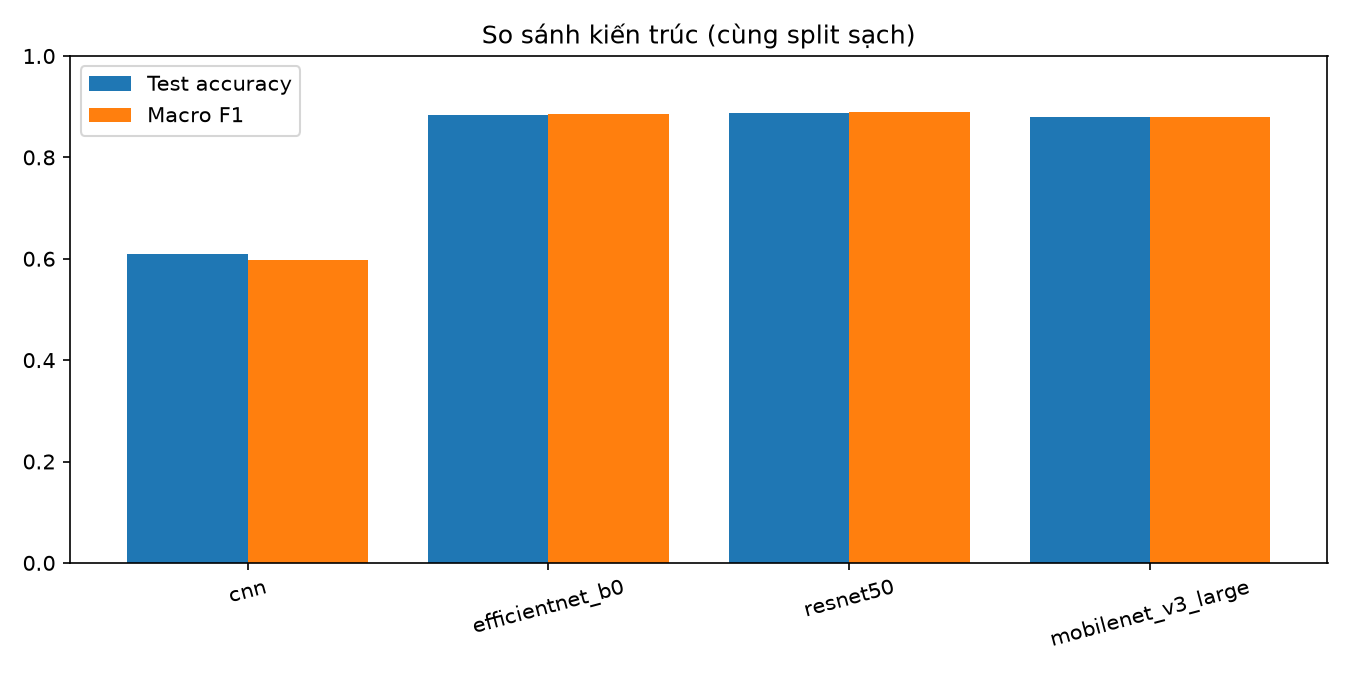

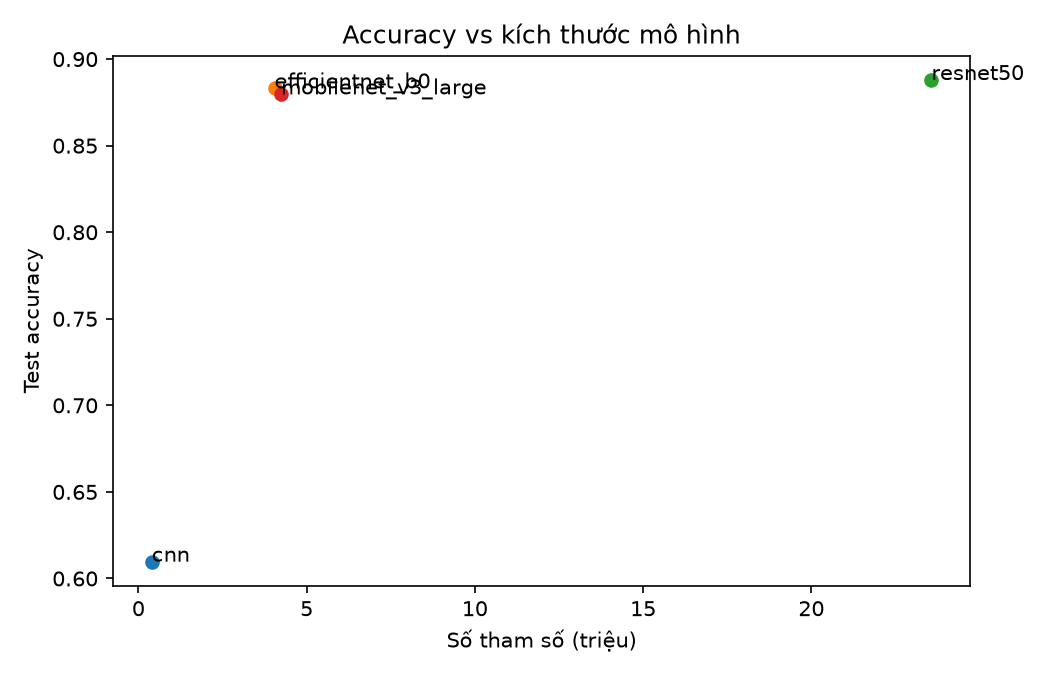

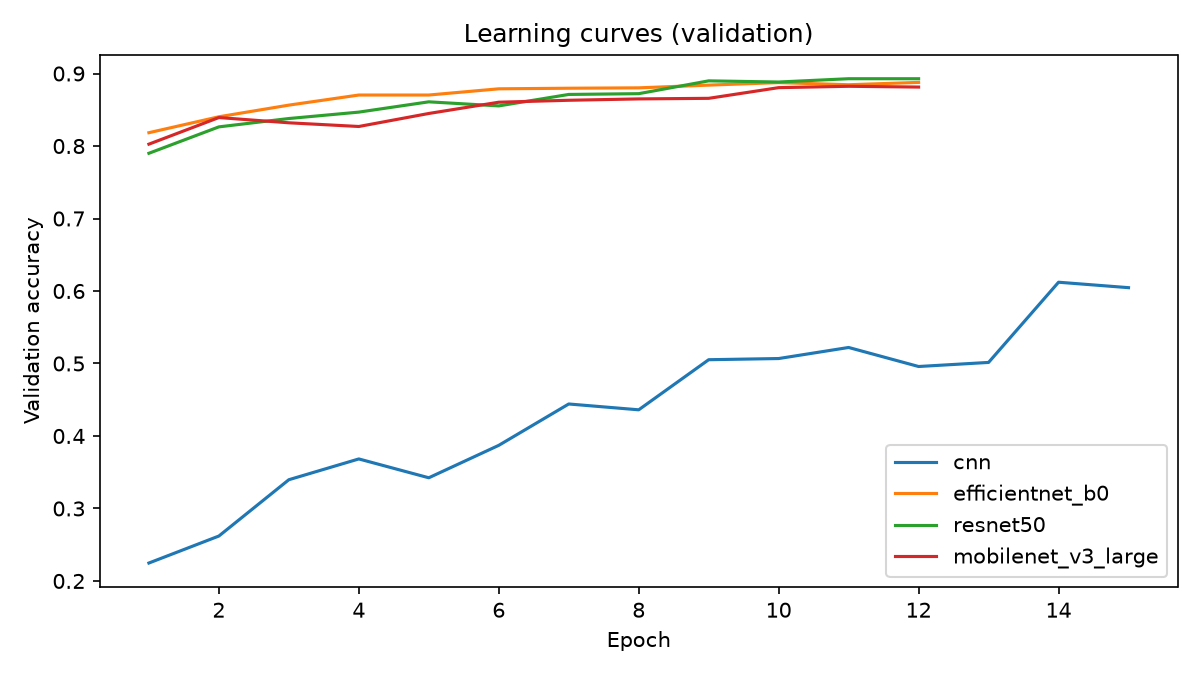

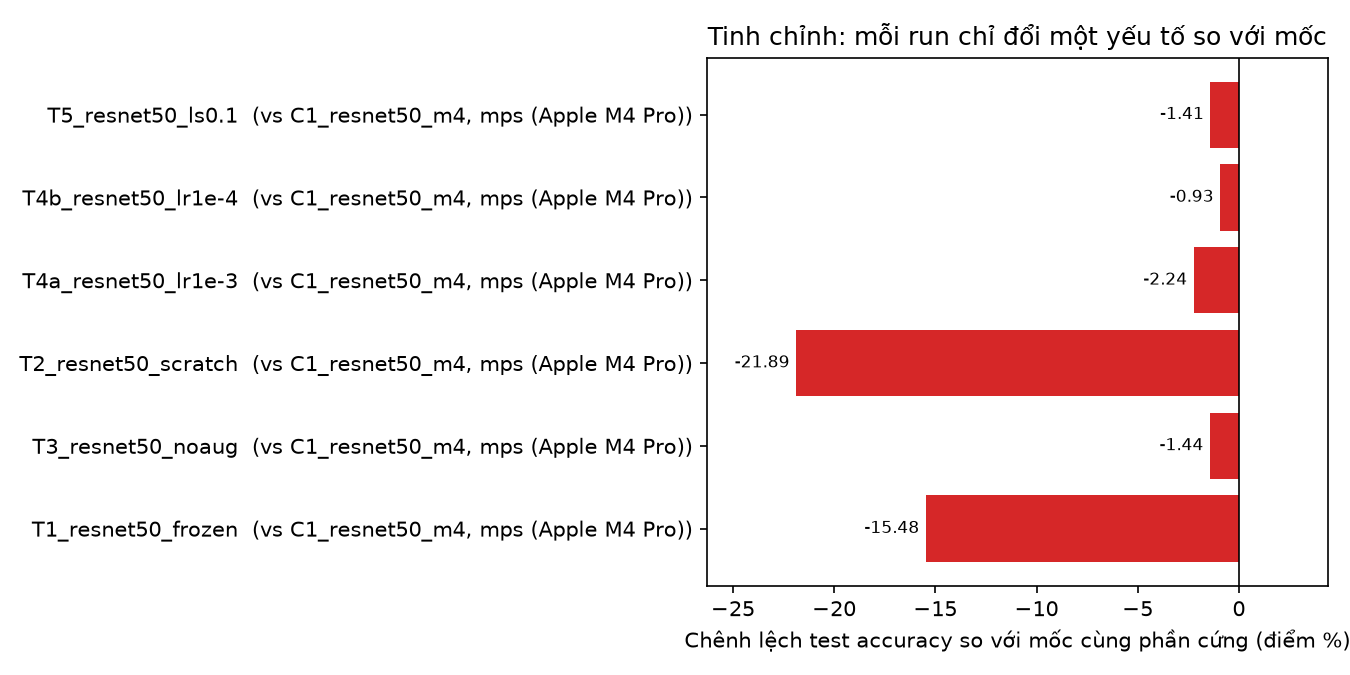

In [4]:
for name in ("comparison_arch.png", "accuracy_vs_params.png", "learning_curves_all.png", "tuning.png"):
    if (out / name).is_file():
        display(Show(str(out / name)))

## Mô hình cuối: validation accuracy cao nhất trong mọi run

/Users/thanhhhtt/repos/2631/dl/final-project/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Mô hình cuối: E2_resnet50 | val acc 0.8928 | test acc 0.8879
Temperature=1.8029; test ECE 0.0600 -> 0.0132; NLL 0.4726 -> 0.3832


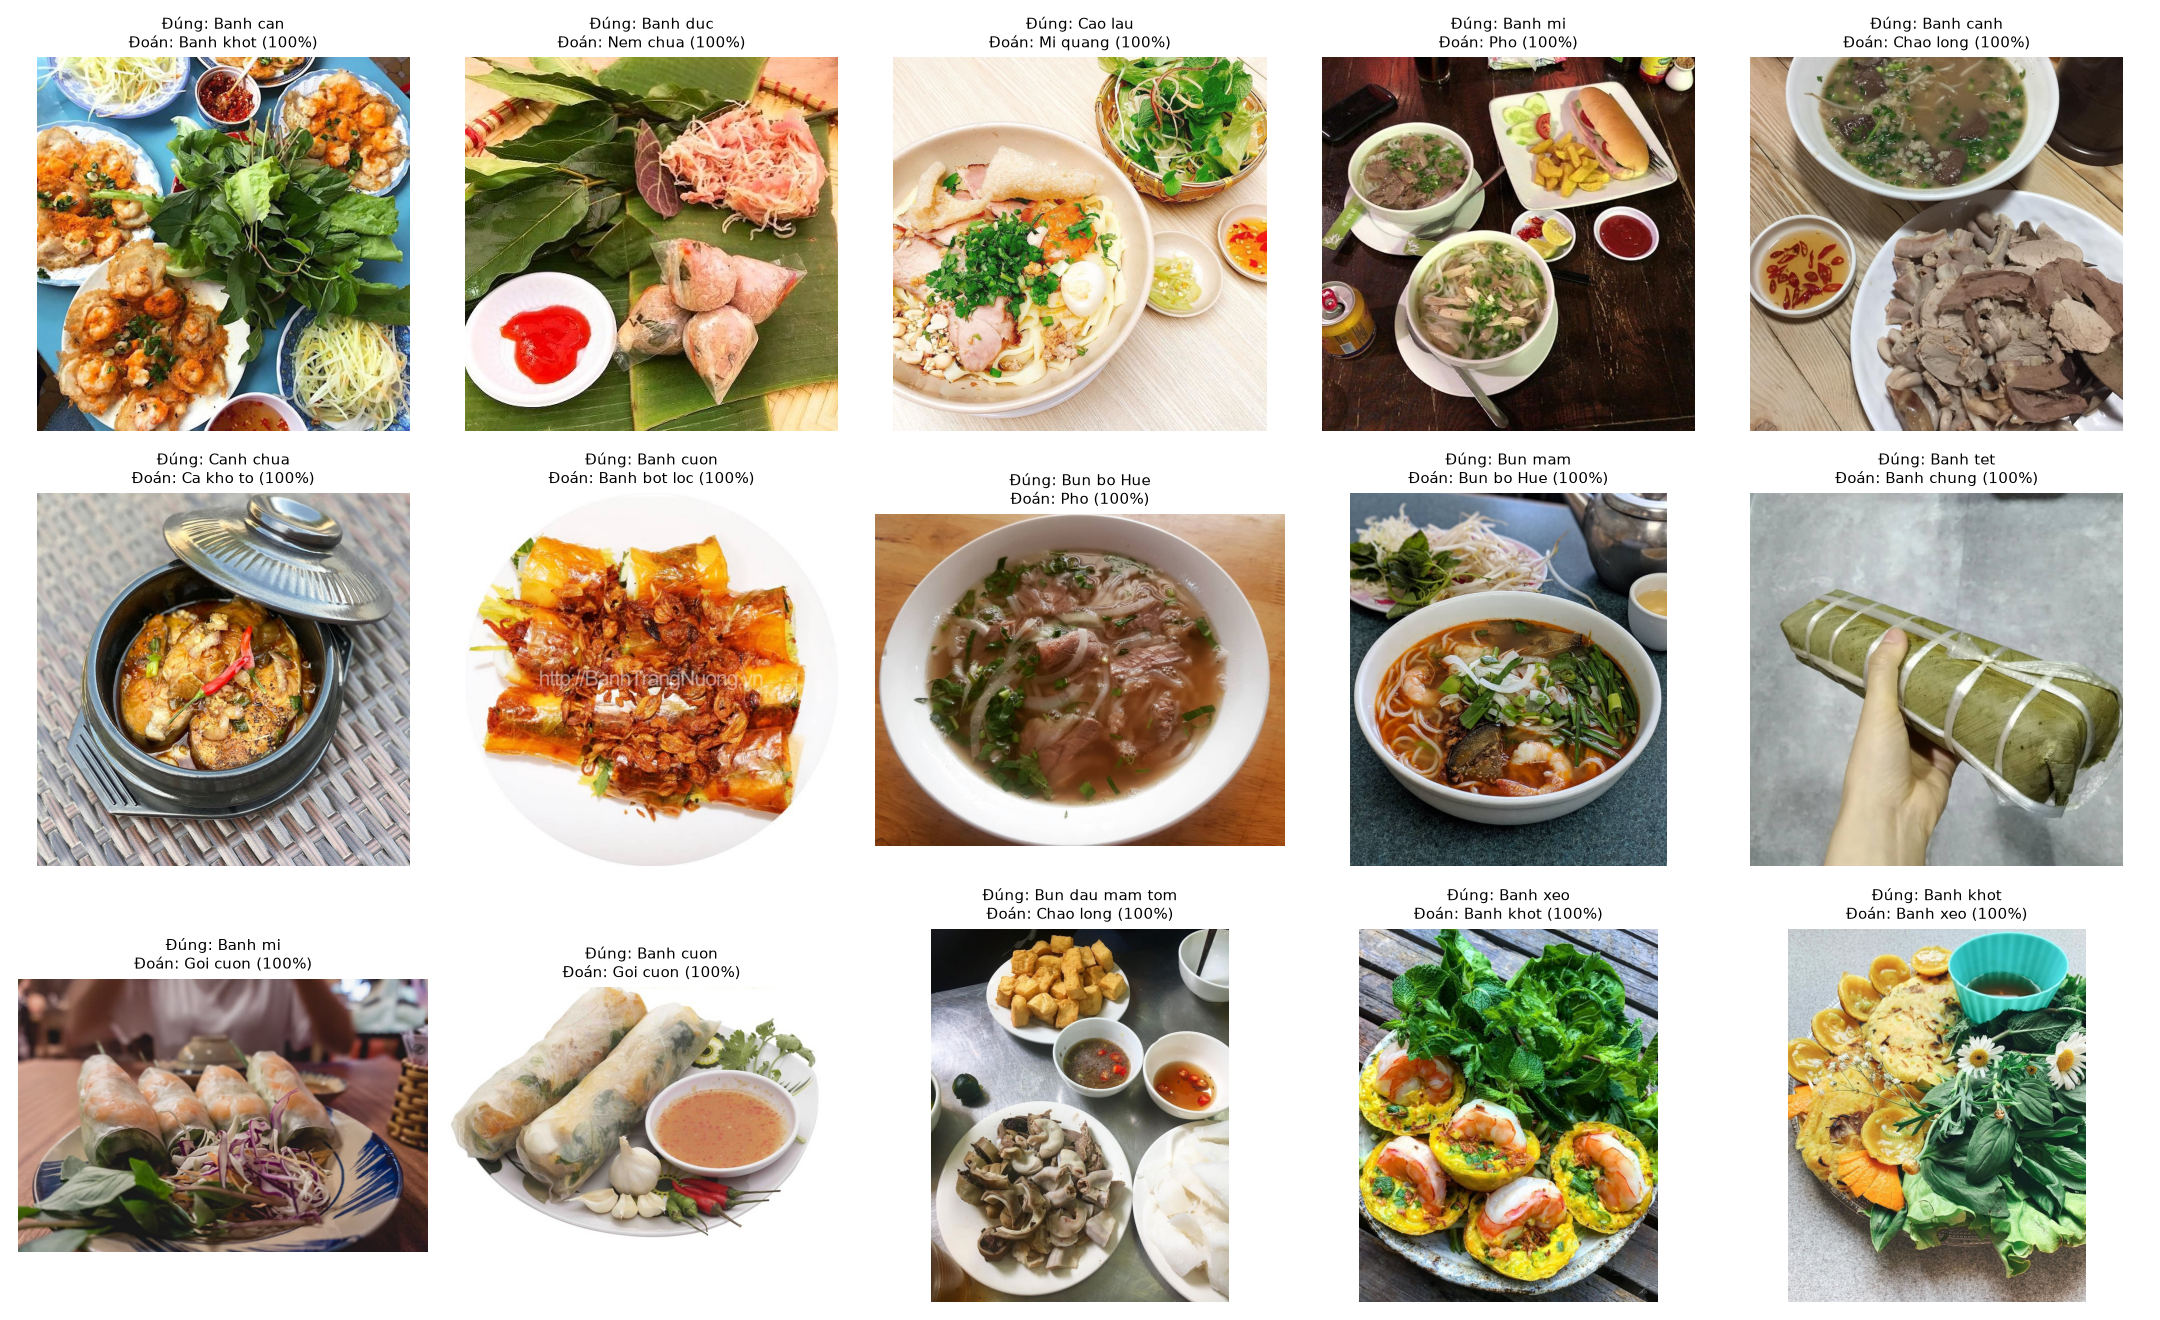

91

In [5]:
from colab import analyze
best = compare.pick_best(rows)
print("Mô hình cuối:", best["run_id"], "| val acc", round(best["best_val_accuracy"], 4),
      "| test acc", round(best["test_accuracy"], 4))
report = analyze.calibrate_run(Path(best["run_dir"]), json.loads(MANIFEST.read_text()),
                               REPO, DEVICE)
print(f"Temperature={report['temperature']:.4f}; test ECE {report['test_before']['ece']:.4f} -> "
      f"{report['test_after']['ece']:.4f}; NLL {report['test_before']['nll']:.4f} -> {report['test_after']['nll']:.4f}")
display(Show(str(analyze.misclassified_gallery(Path(best["run_dir"]), REPO))))
(out / "final.json").write_text(json.dumps({"run_id": best["run_id"], "arch": best["arch"],
                                            "reason": "best validation accuracy"}, indent=2))